# Chapter 6: Benchmarking Approximate Search

Approximate nearest-neighbor methods are usually compared by their **recall against exact
search**: which fraction of the true top 10 does the method return? This is the axis of the
public [ann-benchmarks](https://github.com/erikbern/ann-benchmarks) plots and of demo
ch06-02, where the exact top 10 was the reference for every method.
But a user never sees "the true top 10". A user sees the result of a retrieval pipeline, and
in Chapter 5 that pipeline was a fast retriever followed by a reranker. What counts is the
precision and recall of that final result, measured against relevance judgments, not how
accurately the dense search reproduces the exact neighbors. This notebook asks the question
that matters for such a pipeline: **if the retriever searches approximately, how much worse
does the final ranking become?**

We answer it with real relevance judgments. The retriever is built from the three components
of the chapter:

1. **Matryoshka embeddings** truncated to 1024, 512, 256, 128, or 64 dimensions,
2. a **coarse filter** that decides which vectors to examine (full scan, IVF, or HNSW),
3. a **fine filter** that decides how cheaply to compare them (exact floats, PQ codes, or LSH bits).

Each retriever returns its top 50; a cross-encoder reranks them into the final top 10.

**Learning goals:**
- Build IVF, PQ, and LSH retrievers from components and measure their cost per query
- See why recall against exact search understates the quality of approximate retrieval
- Understand which errors a reranker can repair (fine filter) and which it cannot (coarse filter)
- Judge how incomplete relevance judgments bias an evaluation, and how an LLM judge can complete them

**Prerequisites:** ch06-02 (ANN methods), ch05-05 (retriever and reranker pipelines), Chapter 2 (nDCG)

## Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from shared.display import print_table, display_md
from shared.collections import load_collection
from shared.assessments import load_assessments, load_judgments
from ch06_ann import (truncate, Retriever, AllVectors, IVF, Exact, PQ, LSH,
                      load_benchmark, evaluate, bootstrap_ci, REFERENCE)

EVAL_DIR = Path("eval/ch06_ann")

def run_label(run_name):
    """Run names contain '|', which would split a Markdown table cell."""
    return run_name.replace(" | ", ", ")

<div style="border-left: 4px solid #64748B; background: rgba(100, 116, 139, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#64748B; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">What runs live and what is pre-computed</strong><br>
Encoding the 171,332 abstracts with a 0.6B-parameter embedding model takes about 17 minutes on a recent GPU and many hours on a laptop CPU. The full benchmark therefore ran offline with <a href="eval/ch06_ann/run_benchmark.py"><code>eval/ch06_ann/run_benchmark.py</code></a>, and the LLM judgments with <a href="eval/ch06_ann/judge.py"><code>eval/ch06_ann/judge.py</code></a>. This notebook loads their results. Section 2 runs the same components live on a 15,000-document sample, which takes seconds on any laptop. The components themselves live in <a href="ch06_ann.py"><code>ch06_ann.py</code></a>.
</div>

## 1. The collection and its judgments

TREC-COVID is part of the BEIR benchmark: 171,332 abstracts of COVID-19 research papers and 50
information needs (topics). Each topic has a question, a short keyword form, and a narrative
that tells the assessors what counts as relevant. Human assessors judged documents on three
grades: 0 (not relevant), 1 (partially relevant), and 2 (relevant).

In [2]:
collection = load_collection("trec-covid")
assessments = load_assessments("trec-covid")

topic = assessments.topics["1"]
grades = [g for labels in assessments.qrels.values() for g in labels.values()]
display_md(
    f"**{len(collection):,} documents, {len(assessments.topics)} topics, "
    f"{len(grades):,} judgments** ({len(grades) / len(assessments.topics):,.0f} per topic)\n\n"
    f"| Grade | Judgments |\n|---|---|\n"
    + "\n".join(f"| {g} | {grades.count(g):,} |" for g in (0, 1, 2))
    + f"\n\n**Topic 1.** Question: *{topic.question}*  \n"
    f"Narrative: *{topic.narrative}*"
)

**171,332 documents, 50 topics, 66,336 judgments** (1,327 per topic)

| Grade | Judgments |
|---|---|
| 0 | 41,663 |
| 1 | 10,456 |
| 2 | 14,217 |

**Topic 1.** Question: *what is the origin of COVID-19*  
Narrative: *seeking range of information about the SARS-CoV-2 virus's origin, including its evolution, animal source, and first transmission into humans*

These judgments are deep, but they are not complete. TREC assessors judged the documents that
the systems of 2020 retrieved. An approximate retriever may surface a document that nobody
ever judged, and the standard evaluation silently counts it as not relevant. We return to this
problem in Section 4.

## 2. The three components, live on a sample

We load 15,000 random abstracts and the 50 topic queries, embedded with the Matryoshka-trained
model Qwen3-Embedding-0.6B and truncated to 256 dimensions. Exact search over the sample is
our reference.

In [3]:
sample = np.load(EVAL_DIR / "sample_256.npz")
X = sample["docs"].astype(np.float32)
Q = sample["queries"].astype(np.float32)

exact = Retriever(AllVectors(), Exact()).fit(X)
reference = [exact.search(q, 10)[0] for q in Q]
display_md(f"**Sample:** {X.shape[0]:,} documents x {X.shape[1]} dimensions, {len(Q)} queries")

**Sample:** 15,000 documents x 256 dimensions, 50 queries

Each retriever below combines one coarse and one fine filter. For each, we measure how many of
the exact top 10 it finds (recall@10) and how many bytes of vector data it reads per query.

In [4]:
def compare(retrievers, X, Q, reference, full_scan_bytes=None):
    """Fit retrievers on X and report recall@10 against `reference` and the cost per query."""
    full_scan_bytes = full_scan_bytes or X.shape[0] * X.shape[1] * 4
    rows = []
    for r in retrievers:
        r.fit(X)
        results = [r.search(q, 10) for q in Q]
        recall = np.mean([len(set(ids) & set(ref)) / 10 for (ids, _), ref in zip(results, reference)])
        cost = np.mean([c.bytes for _, c in results])
        rows.append([r.name, f"{recall:.2f}", f"{np.mean([c.vectors for _, c in results]):,.0f}",
                     f"{cost / 1e3:,.0f} KB", f"1/{full_scan_bytes / cost:,.0f}"])
    print_table(rows, headers=["Retriever", "Recall@10", "Vectors scored", "Bytes read", "vs. full scan"])

compare([Retriever(AllVectors(), Exact()),
         Retriever(IVF(nlist=128, nprobe=4), Exact()),
         Retriever(AllVectors(), PQ(m=32)),
         Retriever(AllVectors(), LSH(nbits=512)),
         Retriever(IVF(nlist=128, nprobe=4), PQ(m=32))], X, Q, reference)

| Retriever                 |   Recall@10 |   Vectors scored | Bytes read   | vs. full scan   |
|:--------------------------|------------:|-----------------:|:-------------|:----------------|
| all + exact               |        1    |           15,000 | 15,360 KB    | 1/1             |
| IVF128 nprobe=4 + exact   |        0.8  |              589 | 735 KB       | 1/21            |
| all + PQ 32 B             |        0.6  |           15,000 | 480 KB       | 1/32            |
| all + LSH 512 bit         |        0.54 |           15,000 | 960 KB       | 1/16            |
| IVF128 nprobe=4 + PQ 32 B |        0.53 |              589 | 150 KB       | 1/102           |

The coarse filter (IVF) reduces *how many* vectors are scored; the fine filters (PQ, LSH)
reduce *how many bytes* each comparison reads. Combined, the savings multiply, and so do the
losses in recall.

Matryoshka truncation is the third lever: the first 64 of the 256 components already form a
usable embedding, at a quarter of the cost. Recall and cost are still measured against the
exact search on 256 dimensions.

In [5]:
X64, Q64 = truncate(X, 64), truncate(Q, 64)
compare([Retriever(AllVectors(), Exact()),
         Retriever(IVF(nlist=128, nprobe=4), PQ(m=16))], X64, Q64, reference,
        full_scan_bytes=X.shape[0] * X.shape[1] * 4)

| Retriever                 |   Recall@10 |   Vectors scored | Bytes read   | vs. full scan   |
|:--------------------------|------------:|-----------------:|:-------------|:----------------|
| all + exact               |        0.55 |           15,000 | 3,840 KB     | 1/4             |
| IVF128 nprobe=4 + PQ 16 B |        0.37 |              683 | 44 KB        | 1/352           |

**Observation:** by recall against exact search, every one of these retrievers looks poor. The
question is whether the documents they miss are actually better than the ones they return.

## 3. The full benchmark

The offline benchmark ran every combination on the full collection: 5 embedding lengths, 6
coarse settings (full scan, IVF with 1, 4, or 16 probed lists out of 1024, HNSW with search
width 50 or 200), and 6 fine filters (exact, PQ with 8, 16, or 32 bytes, LSH with 128 or 512
bits). HNSW computes its own scores during the graph walk, so it runs either on float vectors
or on PQ codes. This gives 140 retrievers. For each topic, each retriever returned its top 50,
and two cross-encoders reranked them into a top 10.

In [6]:
meta, runs = load_benchmark()
display_md(
    f"**{len(runs)} retrievers** over {meta['n_docs']:,} documents  \n"
    f"Embedding model: `{meta['embed_model']}`  \n"
    f"Rerankers: " + ", ".join(f"`{v}`" for v in meta["rerankers"].values()) + "  \n"
    f"A full scan at 1024 dimensions reads {meta['bytes_full_scan'] / 1e6:,.0f} MB per query."
)

**140 retrievers** over 171,332 documents  
Embedding model: `Qwen/Qwen3-Embedding-0.6B`  
Rerankers: `Qwen/Qwen3-Reranker-0.6B`, `cross-encoder/ms-marco-MiniLM-L-6-v2`  
A full scan at 1024 dimensions reads 702 MB per query.

## 4. Completing the judgments with an LLM judge

How many documents in the final top 10 lack a judgment? For exact search almost none, but
approximate retrievers surface documents that TREC never judged.

In [7]:
trec = evaluate(runs, assessments)
worst = min(trec, key=lambda n: trec[n]["judged"].mean())
display_md(
    f"Judged fraction of the reranked top 10: **{trec[REFERENCE]['judged'].mean():.0%}** for exact search, "
    f"but only **{trec[worst]['judged'].mean():.0%}** for `{run_label(worst)}`."
)

Judged fraction of the reranked top 10: **98%** for exact search, but only **78%** for `d=1024, all + PQ 8 B`.

Each unjudged document counts as "not relevant", which penalizes exactly the retrievers we
want to evaluate. To close the gap, an LLM judge (Claude) graded all 7,838 unjudged
(topic, document) pairs that appear in any top 10, using the TREC-COVID grade definitions and
the topic narrative.

Before trusting the judge, we measure it. It graded 300 pairs that TREC had already judged,
100 per grade, without seeing the TREC grade.

In [8]:
cal = json.loads((EVAL_DIR / "calibration.json").read_text(encoding="utf-8"))
conf = cal["confusion_trec_rows_llm_cols"]
print_table([[f"TREC {i}"] + conf[i] for i in range(3)], headers=["", "LLM 0", "LLM 1", "LLM 2"])
display_md(
    f"Exact agreement **{cal['exact_agreement']:.2f}**, Cohen's kappa **{cal['kappa']:.2f}**; "
    f"binary (relevant or not) agreement **{cal['binary_agreement']:.2f}**, kappa **{cal['binary_kappa']:.2f}**."
)

|        |   LLM 0 |   LLM 1 |   LLM 2 |
|:-------|--------:|--------:|--------:|
| TREC 0 |      77 |      21 |       2 |
| TREC 1 |      32 |      55 |      13 |
| TREC 2 |       8 |      49 |      43 |

Exact agreement **0.58**, Cohen's kappa **0.38**; binary (relevant or not) agreement **0.79**, kappa **0.55**.

The judge agrees with TREC on "relevant or not" about four times out of five. This is moderate
agreement, and human assessors also disagree with each other noticeably on borderline documents. It is stricter than TREC on the top grade: it
often gives a 1 where TREC gave a 2. Its labels for newly surfaced documents are therefore, if
anything, conservative.

<div style="border-left: 4px solid #D97706; background: rgba(217, 119, 6, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#D97706; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">The prompt matters</strong><br>
A first version of the judge prompt was much stricter: it required an article to cover every aspect listed in the narrative, while TREC assessors accepted an article that covers one aspect well. The cell below compares both versions on the same 300 pairs.
</div>

In [9]:
detail = [json.loads(l) for l in (EVAL_DIR / "judgments_llm_detail.jsonl").read_text(encoding="utf-8").splitlines()]
rows = []
for tag, label in [("calibration", "v1: cover all aspects"), ("calibration-v2", "v2: one aspect suffices")]:
    pairs = [(r["grade"], assessments.grade(r["query"], r["doc"])) for r in detail if r["tag"] == tag]
    binary = np.mean([(llm > 0) == (human > 0) for llm, human in pairs])
    rejected = np.mean([llm == 0 for llm, human in pairs if human == 2])
    rows.append([label, len(pairs), f"{binary:.2f}", f"{rejected:.0%}"])
print_table(rows, headers=["Judge prompt", "Pairs", "Binary agreement", "TREC 2 judged as 0"])

| Judge prompt            |   Pairs |   Binary agreement | TREC 2 judged as 0   |
|:------------------------|--------:|-------------------:|:---------------------|
| v1: cover all aspects   |     300 |               0.75 | 14%                  |
| v2: one aspect suffices |     300 |               0.79 | 8%                   |

We now evaluate every run in three ways: with the TREC judgments only (unjudged counts as not
relevant), with **condensed** rankings (unjudged documents removed before scoring), and with
the judgments **completed** by the LLM judge.

In [10]:
completed = assessments.merge(load_judgments(EVAL_DIR / "judgments_llm.json"), source="llm")
views = {"TREC only": trec,
         "condensed": evaluate(runs, assessments, mode="condensed"),
         "completed": evaluate(runs, completed)}

selected = [REFERENCE, "d=1024 | HNSW M=32 ef=50 + exact", "d=256 | IVF1024 nprobe=16 + PQ 32 B",
            "d=64 | HNSW M=32 ef=50 + exact", "d=1024 | all + PQ 8 B", "d=1024 | IVF1024 nprobe=1 + exact"]
print_table([[run_label(n)] + [f"{views[v][n]['ndcg_rr'].mean():.3f}" for v in views] for n in selected],
            headers=["Retriever (reranked)", "nDCG@10 TREC only", "condensed", "completed"])

| Retriever (reranked)               |   nDCG@10 TREC only |   condensed |   completed |
|:-----------------------------------|--------------------:|------------:|------------:|
| d=1024, all + exact                |               0.909 |       0.913 |       0.919 |
| d=1024, HNSW M=32 ef=50 + exact    |               0.913 |       0.918 |       0.925 |
| d=256, IVF1024 nprobe=16 + PQ 32 B |               0.9   |       0.903 |       0.924 |
| d=64, HNSW M=32 ef=50 + exact      |               0.901 |       0.904 |       0.92  |
| d=1024, all + PQ 8 B               |               0.722 |       0.743 |       0.805 |
| d=1024, IVF1024 nprobe=1 + exact   |               0.825 |       0.833 |       0.864 |

**Observation:** completing the judgments raises the approximate retrievers more than exact
search. Part of what looked like a loss of quality was a gap in the judgments.

## 5. Recall versus quality

Now the central comparison. We measure every one of the 140 retrievers in three ways. The
first measure compares the retriever with exact search; the other two compare results with
the relevance judgments (completed by the LLM judge):

| Measure | What is compared | Against what | Question it answers |
|---|---|---|---|
| Recall@10 against exact search | the retriever's top 10 | the exact top 10 | How well does the retriever reproduce the nearest neighbors? (the ann-benchmarks view) |
| nDCG@10, retriever alone | the retriever's top 10 | the relevance judgments | How good would the result be without a reranker? |
| nDCG@10 after reranking | the reranker's top 10, chosen from the retriever's top 50 | the relevance judgments | How good is the result the user sees? |

The first measure needs no judgments at all: a document that is relevant but not among the
exact nearest neighbors counts as a miss. The other two do not care whether a document is a
nearest neighbor, only whether it is relevant.

In the plots, each point is one retriever. The x-axis shows how much less data it reads than
a full scan; the dashed lines mark exact search.

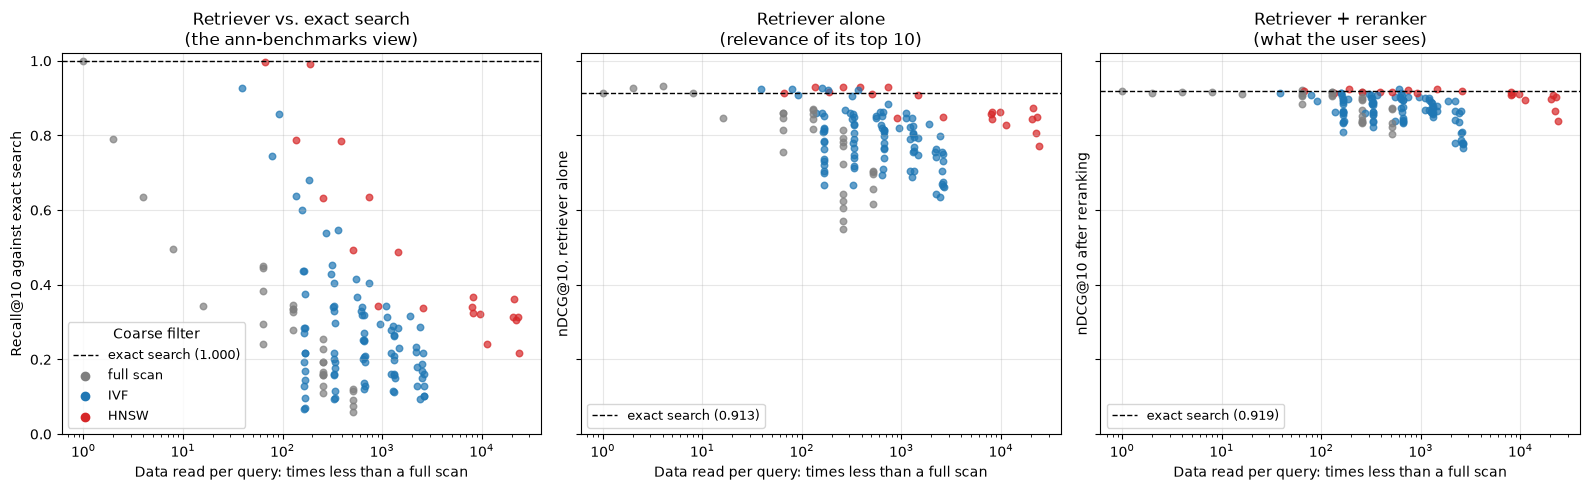

In [11]:
ev = views["completed"]
full = meta["bytes_full_scan"]
colors = {"all": "tab:gray", "IVF": "tab:blue", "HNSW": "tab:red"}
panels = [("recall10", "Retriever vs. exact search\n(the ann-benchmarks view)", "Recall@10 against exact search"),
          ("ndcg_ret", "Retriever alone\n(relevance of its top 10)", "nDCG@10, retriever alone"),
          ("ndcg_rr", "Retriever + reranker\n(what the user sees)", "nDCG@10 after reranking")]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for name, r in ev.items():
    family = next((f for f in ("IVF", "HNSW") if r["coarse"].startswith(f)), "all")
    for ax, (key, _, _) in zip(axes, panels):
        ax.scatter(full / r["bytes"], r[key].mean(), c=colors[family], s=22, alpha=0.7)
for ax, (key, title, ylabel) in zip(axes, panels):
    ref_value = ev[REFERENCE][key].mean()
    ax.axhline(ref_value, color="black", linestyle="--", linewidth=1, label=f"exact search ({ref_value:.3f})")
    ax.set_xscale("log"); ax.set_title(title); ax.set_ylabel(ylabel); ax.set_ylim(0, 1.02)
    ax.set_xlabel("Data read per query: times less than a full scan"); ax.grid(True, alpha=0.3)
    ax.legend(loc="lower left", fontsize=9)
for fam, c in colors.items():
    axes[0].scatter([], [], c=c, label="full scan" if fam == "all" else fam)
axes[0].legend(title="Coarse filter", loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

The three panels tell three different stories about the same retrievers. We summarize them
for the retrievers that read at least 100 times less data than a full scan:

In [12]:
cheap = [r for r in ev.values() if full / r["bytes"] >= 100]
rows = []
for key, _, label in panels:
    values = np.array([r[key].mean() for r in cheap])
    exact_value = ev[REFERENCE][key].mean()
    rows.append([label, f"{exact_value:.3f}", f"{np.median(values):.3f}",
                 f"{np.mean(values >= exact_value - 0.03):.0%}"])
print_table(rows, headers=["Measure", "Exact search", "Median of the cheap retrievers",
                           "Within 0.03 of exact search"])
display_md(f"**{len(cheap)} of {len(ev)} retrievers** read at least 100 times less data than a full scan.")

| Measure                        |   Exact search |   Median of the cheap retrievers | Within 0.03 of exact search   |
|:-------------------------------|---------------:|---------------------------------:|:------------------------------|
| Recall@10 against exact search |          1     |                            0.237 | 1%                            |
| nDCG@10, retriever alone       |          0.913 |                            0.802 | 10%                           |
| nDCG@10 after reranking        |          0.919 |                            0.877 | 44%                           |

**126 of 140 retrievers** read at least 100 times less data than a full scan.

- **Left: the retriever against exact search.** Recall collapses as soon as the retriever
  saves data. The typical cheap retriever returns only about a quarter of the exact top 10.
  By this measure, approximate search looks like a failure.
- **Middle: the retriever alone, judged for relevance.** The same retrievers lose far less
  quality than their recall suggests. The documents they return instead of the exact
  neighbors are often just as relevant: in high dimensions, the exact neighbors are only
  marginally nearer than the next candidates (ch06-01), and many of those candidates are
  good matches too. Recall against exact search therefore understates the quality of the
  retriever itself.
- **Right: the full pipeline.** The reranker closes most of the remaining gap, as long as the
  good matches are among the 50 candidates it receives. Many cheap retrievers end within 0.03
  of exact search. Section 6 looks at the ones that do not, and why the reranker cannot help
  them.

The table below follows the selected retrievers through all three measures. The last column
compares the final result with exact search and gives a 95 percent bootstrap interval over
the 50 topics: an interval that contains 0 means the difference is within the noise.

In [13]:
ref = ev[REFERENCE]["ndcg_rr"]
rows = []
for n in selected:
    diff = ev[n]["ndcg_rr"] - ref
    lo, hi = bootstrap_ci(diff)
    rows.append([run_label(n), f"1/{full / ev[n]['bytes']:,.0f}", f"{ev[n]['recall10'].mean():.2f}",
                 f"{ev[n]['ndcg_ret'].mean():.3f}", f"{ev[n]['ndcg_rr'].mean():.3f}",
                 f"{diff.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]"])
print_table(rows, headers=["Retriever", "Data read", "Recall@10 vs. exact", "nDCG@10 alone",
                           "nDCG@10 reranked", "Reranked vs. exact [95% CI]"])

| Retriever                          | Data read   |   Recall@10 vs. exact |   nDCG@10 alone |   nDCG@10 reranked | Reranked vs. exact [95% CI]   |
|:-----------------------------------|:------------|----------------------:|----------------:|-------------------:|:------------------------------|
| d=1024, all + exact                | 1/1         |                  1    |           0.913 |              0.919 | +0.000 [+0.000, +0.000]       |
| d=1024, HNSW M=32 ef=50 + exact    | 1/188       |                  0.99 |           0.917 |              0.925 | +0.006 [+0.001, +0.014]       |
| d=256, IVF1024 nprobe=16 + PQ 32 B | 1/608       |                  0.33 |           0.863 |              0.924 | +0.005 [-0.018, +0.027]       |
| d=64, HNSW M=32 ef=50 + exact      | 1/2,604     |                  0.34 |           0.848 |              0.92  | +0.001 [-0.025, +0.024]       |
| d=1024, all + PQ 8 B               | 1/512       |                  0.06 |           0.656 |              0.805 | -0.114 [-0.167, -0.065]       |
| d=1024, IVF1024 nprobe=1 + exact   | 1/137       |                  0.64 |           0.861 |              0.864 | -0.056 [-0.104, -0.015]       |

Take the retriever with 256 dimensions, 16 probed lists, and 32-byte PQ codes. It reads 608
times less data and finds only a third of the exact top 10. Alone, its result is clearly
worse than exact search; after reranking, it is as good. Recall against exact search and the
quality of the final result are different things.

## 6. What the reranker repairs, and what it cannot

The reranker sees only the 50 documents the retriever hands over. It can fix their *order*, but
it cannot bring back a document that was never retrieved. The two kinds of approximation fail
in these two different ways.

In [14]:
cases = ["d=1024 | all + PQ 8 B", "d=1024 | IVF1024 nprobe=1 + exact", REFERENCE]
print_table([[run_label(n), f"{ev[n]['ndcg_ret'].mean():.3f}", f"{ev[n]['ndcg_rr'].mean():.3f}",
              f"{ev[n]['ndcg_rr'].mean() - ev[n]['ndcg_ret'].mean():+.3f}"] for n in cases],
            headers=["Retriever", "nDCG@10 retriever", "nDCG@10 reranked", "Repaired by reranker"])

| Retriever                        |   nDCG@10 retriever |   nDCG@10 reranked |   Repaired by reranker |
|:---------------------------------|--------------------:|-------------------:|-----------------------:|
| d=1024, all + PQ 8 B             |               0.656 |              0.805 |                  0.149 |
| d=1024, IVF1024 nprobe=1 + exact |               0.861 |              0.864 |                  0.002 |
| d=1024, all + exact              |               0.913 |              0.919 |                  0.006 |

PQ with 8 bytes per vector ranks badly, but many relevant documents are still among its top
50, and the reranker lifts them back up: it repairs more than half of the gap to exact search. IVF with a single probed list misses neighbors that sit
in other clusters; the reranker never sees them. **Fine-filter errors are repairable,
coarse-filter errors are not.** This is why production systems keep the coarse filter generous
and let the fine filter be aggressive.

The repair only works if the reranker is better than the retriever. The ms-marco MiniLM
cross-encoder from Chapter 5 is weaker than the Qwen3 retriever used here:

In [15]:
ev_minilm = evaluate(runs, completed, reranker="minilm")
display_md(
    f"Exact search: retriever alone **{ev[REFERENCE]['ndcg_ret'].mean():.3f}**, "
    f"reranked by Qwen3-Reranker **{ev[REFERENCE]['ndcg_rr'].mean():.3f}**, "
    f"reranked by ms-marco MiniLM **{ev_minilm[REFERENCE]['ndcg_rr'].mean():.3f}**."
)

Exact search: retriever alone **0.913**, reranked by Qwen3-Reranker **0.919**, reranked by ms-marco MiniLM **0.867**.

## 7. Fewer dimensions

The Matryoshka lever deserves a closer look. How much does the final result suffer when the
embeddings are truncated?

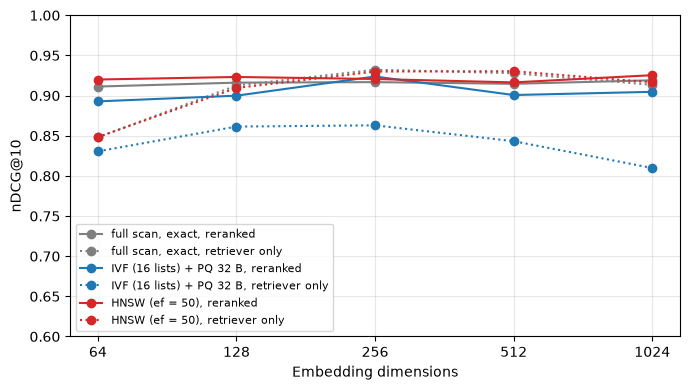

In [16]:
dims = [1024, 512, 256, 128, 64]
fig, ax = plt.subplots(figsize=(7, 4))
for (coarse_fine, label), color in zip([("all + exact", "full scan, exact"),
                                        ("IVF1024 nprobe=16 + PQ 32 B", "IVF (16 lists) + PQ 32 B"),
                                        ("HNSW M=32 ef=50 + exact", "HNSW (ef = 50)")],
                                       ["tab:gray", "tab:blue", "tab:red"]):
    for key, style in [("ndcg_rr", "-"), ("ndcg_ret", ":")]:
        ax.plot(dims, [ev[f"d={d} | {coarse_fine}"][key].mean() for d in dims], style, marker="o",
                color=color, label=f"{label}, {'reranked' if key == 'ndcg_rr' else 'retriever only'}")
ax.set_xscale("log", base=2); ax.set_xticks(dims, [str(d) for d in dims])
ax.set_xlabel("Embedding dimensions"); ax.set_ylabel("nDCG@10"); ax.set_ylim(0.6, 1)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The retriever alone (dotted) does not simply get worse with fewer dimensions. The full scan
works best around 256 dimensions and drops only at 64. For IVF with 32-byte PQ codes, more
dimensions even hurt: the code size stays fixed, so each byte must summarize a longer
sub-vector. After reranking (solid), all three curves stay within about 0.03 of exact search
at every length, down to 64 dimensions: a sixteenth of the storage and of the comparison cost.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Good matches are enough</strong><br>
On TREC-COVID, retrievers that read hundreds or thousands of times less data than a full scan, and that return only a third of the exact top 10, deliver a reranked result within a few points of exact search. Recall against exact search measures the wrong thing for a retrieval pipeline: the quality of the final result decides, not how accurately the dense search reproduces the exact neighbors. What matters is that the good matches reach the reranker.
</div>

## Summary

| Finding | Evidence in this notebook |
|---|---|
| Recall against exact search understates quality | Section 5: recall collapses, nDCG@10 after reranking stays close to exact search |
| The reranker repairs fine-filter errors | Section 6: PQ 8 B recovers more than half of its loss |
| The reranker cannot repair coarse-filter errors | Section 6: IVF with one probe stays far below exact search |
| The reranker must be stronger than the retriever | Section 6: a weak reranker lowers the result |
| Incomplete judgments bias against new retrievers | Section 4: completing them raises approximate retrievers most |
| Matryoshka truncation is cheap after reranking | Section 7: 64 dimensions stay close to 1024 |

**Limits of this benchmark:** one collection, 50 topics, one embedding model; the LLM judge
agrees with TREC only moderately; costs count vector bytes but not graph links or code tables.

## Try it yourself

1. In Section 2, change `nprobe` from 4 to 1 and to 16. How do recall and bytes read change?
2. In Section 2, compare `PQ(m=8)`, `PQ(m=16)`, and `PQ(m=32)` with the full scan. Which one
   would you hand to a reranker, and why?
3. In Section 5, colour the points by the fine filter instead of the coarse filter. Which fine
   filter keeps nDCG@10 closest to exact search at the lowest cost?